# Backtest sur cours journaliers

**Suite du notebook `portefeuille_simule.ipynb`.** Le premier notebook travaillait avec un cours par semaine : la règle stop-loss / take-profit ne voyait que le cours de fin de semaine, ce qui avantage artificiellement les stop-loss serrés.

Ici, on télécharge les cours **journaliers** (ouverture, plus haut, plus bas, clôture) pour :

1. contrôler que les tickers correspondent bien aux cours du classeur ;
2. retrouver le **vrai jour de déclenchement** des ordres et leur prix d'exécution, gaps d'ouverture compris ;
3. mesurer le risque au jour le jour : **volatilité annualisée, VaR historique, ratio de Sharpe** ;
4. refaire la **grille des seuils** sans le biais hebdomadaire.

> **Sur Google Colab** : dépose les trois CSV dans un dossier `data`, puis exécute tout (*Exécution → Tout exécuter*). Les cours sont téléchargés une fois puis enregistrés dans `data/cours_journaliers.csv`.

## 1. Paramètres et données

In [4]:
# %pip install -q yfinance   # à décommenter si yfinance n'est pas installé
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("data")
CAPITAL_INITIAL = 2_000_000
TAUX_CASH = 0.03          # rémunération du cash, utilisée aussi comme taux sans risque
BASE_JOURS = 360
JOURS_BOURSE = 252        # pour annualiser

semaines = pd.read_csv(DATA / "semaines.csv")
positions = pd.read_csv(DATA / "positions.csv")
for c in ["date_debut", "date_fin"]:
    semaines[c] = pd.to_datetime(semaines[c])

COULEURS = {"hebdo": "#8D99AE", "journalier": "#1F3A5F", "toutes": "#2A9D8F", "sans": "#E9C46A",
            "cac": "#B56576", "sp": "#6D597A", "var": "#E76F51"}
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11, "axes.titleweight": "bold"})
pct = lambda x: f"{x:+.2%}"
eur = lambda x: f"{x:,.0f} €".replace(",", " ")

## 2. Téléchargement des cours journaliers

In [5]:
CACHE = DATA / "cours_journaliers.csv"
DEBUT, FIN = "2025-09-24", "2025-12-16"
INDICES_YF = {"^FCHI": "CAC 40", "^GSPC": "S&P 500"}
# Sartorius : deux sociétés cotées possibles, on garde celle dont le cours colle au classeur
CANDIDATS = {"DIM.PA": ["DIM.PA", "SRT3.DE"]}

def telecharger(tickers):
    import yfinance as yf
    morceaux = []
    for t in tickers:
        d = yf.download(t, start=DEBUT, end=FIN, auto_adjust=False, progress=False)
        if d.empty:
            print(f"⚠️ Aucune donnée pour {t}")
            continue
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        d = d[["Open", "High", "Low", "Close"]].reset_index()
        d.columns = ["date", "open", "high", "low", "close"]
        d["ticker"] = t
        morceaux.append(d)
    return pd.concat(morceaux, ignore_index=True)

if CACHE.exists():
    cours = pd.read_csv(CACHE, parse_dates=["date"])
    print("Cours relus depuis", CACHE)
else:
    candidats = {c for liste in CANDIDATS.values() for c in liste}
    a_telecharger = sorted((set(positions.ticker) - set(CANDIDATS)) | candidats | {"EURUSD=X"} | set(INDICES_YF))
    cours = telecharger(a_telecharger)
    cours.to_csv(CACHE, index=False)
    print(f"{cours.ticker.nunique()} séries téléchargées et enregistrées dans {CACHE}")

cours["date"] = pd.to_datetime(cours["date"]).dt.tz_localize(None).dt.normalize()
OHLC = {t: g.set_index("date").sort_index() for t, g in cours.groupby("ticker")}
CLOTURES = cours.pivot(index="date", columns="ticker", values="close").sort_index().ffill()
FX = CLOTURES["EURUSD=X"]   # dollars pour 1 euro, comme dans le classeur

29 séries téléchargées et enregistrées dans data/cours_journaliers.csv


## 3. Contrôle des tickers

Pour chaque société, on compare le cours noté dans le classeur à la clôture Yahoo du même jour. Un écart de quelques pour cent est normal (heure de relevé différente) ; un écart important signale un mauvais ticker.

In [6]:
def cloture(ticker, date):
    """Dernière clôture connue à la date donnée."""
    if ticker not in CLOTURES:
        return np.nan
    s = CLOTURES[ticker].loc[:pd.Timestamp(date)].dropna()
    return s.iloc[-1] if len(s) else np.nan

def premieres_lignes():
    return (positions.merge(semaines[["semaine", "date_debut"]], on="semaine")
            .sort_values("semaine").drop_duplicates("ticker"))

for t, liste in CANDIDATS.items():
    ligne = premieres_lignes().query("ticker == @t")
    if ligne.empty:
        continue
    ligne = ligne.iloc[0]
    ecarts = {c: abs(cloture(c, ligne.date_debut) / ligne.cours_debut - 1) for c in liste}
    ecarts = {c: (e if pd.notna(e) else np.inf) for c, e in ecarts.items()}
    choix = min(ecarts, key=ecarts.get)
    positions.loc[positions.ticker == t, "ticker"] = choix
    print(f"{ligne.societe} : ticker retenu {choix} (écart {ecarts[choix]:.1%})")

p1 = premieres_lignes()
controle = pd.DataFrame({
    "société": p1.societe.values, "ticker": p1.ticker.values, "date": p1.date_debut.dt.date.values,
    "cours classeur": p1.cours_debut.values,
    "clôture Yahoo": [cloture(t, d) for t, d in zip(p1.ticker, p1.date_debut)],
})
controle["écart"] = controle["clôture Yahoo"] / controle["cours classeur"] - 1
suspects = controle[controle["écart"].abs() > 0.03]
print(f"{len(suspects)} ticker(s) avec un écart supérieur à 3 %" if len(suspects) else "Tous les tickers collent au classeur (écart < 3 %).")
controle.sort_values("écart", key=abs, ascending=False).style.format({"cours classeur": "{:.2f}", "clôture Yahoo": "{:.2f}", "écart": "{:+.1%}"})

Sartorius : ticker retenu DIM.PA (écart 0.0%)
Tous les tickers collent au classeur (écart < 3 %).


,société,ticker,date,cours classeur,clôture Yahoo,écart
14,Dassault Aviation,AM.PA,2025-10-16,270.00,274.00,+1.5%
15,Klépierre,LI.PA,2025-10-16,32.86,33.16,+0.9%
16,Gtt,GTT.PA,2025-10-16,159.10,160.00,+0.6%
24,Amundi,AMUN.PA,2025-12-04,68.20,68.50,+0.4%
0,Tesla,TSLA,2025-10-01,461.38,459.46,-0.4%
19,Wheaton Precious Metals,WPM,2025-11-12,108.20,107.77,-0.4%
13,Gecina,GFC.PA,2025-10-09,82.05,81.75,-0.4%
12,Peabody Energy,BTU,2025-10-09,31.74,31.84,+0.3%
2,Meta,META,2025-10-01,718.78,717.34,-0.2%
1,Amazon,AMZN,2025-10-01,221.00,220.63,-0.2%


## 4. Moteur de calcul journalier

Même logique que le premier notebook (méthode corrigée), avec une différence : en mode **journalier**, on parcourt chaque jour de la semaine et on vend dès que :

- le **plus bas** du jour touche le seuil de stop-loss → vente au seuil, ou à l'ouverture si le titre a ouvert en dessous (gap) ;
- le **plus haut** du jour touche le seuil de take-profit → vente au seuil, ou à l'ouverture si le titre a ouvert au-dessus.

Si les deux seuils sont touchés le même jour, on retient le stop-loss (hypothèse prudente, l'ordre des cours dans la journée étant inconnu). Le produit de la vente est converti au taux EUR/USD du jour et rémunéré jusqu'à la fin de la semaine.

Le mode **hebdo** reproduit le premier notebook, ce qui permet de comparer les deux à positions identiques.

In [7]:
def chercher_declenchement(ticker, debut, fin, niveau_sl, niveau_tp):
    """Premier jour où le seuil SL ou TP est touché. Renvoie (état, date, prix d'exécution)."""
    jours = OHLC[ticker].loc[(OHLC[ticker].index > debut) & (OHLC[ticker].index <= fin)]
    for date, b in jours.iterrows():
        if b.low <= niveau_sl:
            return "Vendre (SL)", date, min(b.open, niveau_sl)
        if b.high >= niveau_tp:
            return "Vendre (TP)", date, max(b.open, niveau_tp)
    return "Actif", pd.NaT, np.nan


def calculer_semaine(capital_debut, sem, pos, mode="journalier", regle="classeur",
                     seuil_sl=None, seuil_tp=None, execution_notee=True):
    """mode : "journalier" ou "hebdo" ; regle : "classeur", "toutes" ou "aucune"."""
    sl = sem.seuil_sl if seuil_sl is None else seuil_sl
    tp = sem.seuil_tp if seuil_tp is None else seuil_tp
    p = pos.copy().reset_index(drop=True)
    usd = p.devise.eq("USD")
    p["valeur_debut"] = p.nb_actions * np.where(usd, p.cours_debut / sem.fx_debut, p.cours_debut)
    p["valeur_fin"] = p.nb_actions * np.where(usd, p.cours_fin / sem.fx_fin, p.cours_fin)

    regle_active = regle != "aucune" and pd.notna(sl) and pd.notna(tp)
    surveillee = (p.regle_sl_tp.astype(bool) if regle == "classeur" else pd.Series(True, index=p.index)) & regle_active

    etats, dates, prix, fx_exec, jours = [], [], [], [], []
    for row, surv, en_usd in zip(p.itertuples(), surveillee, usd):
        etat, date, px, fx, j = "Actif", pd.NaT, np.nan, 1.0, 0
        if surv:
            niveau_sl, niveau_tp = sl * row.cours_debut, tp * row.cours_debut
            if mode == "journalier":
                etat, date, px = chercher_declenchement(row.ticker, sem.date_debut, sem.date_fin, niveau_sl, niveau_tp)
                if etat != "Actif":
                    fx = FX.loc[:date].iloc[-1] if en_usd else 1.0
                    j = (sem.date_fin - date).days
            else:
                if row.cours_fin > niveau_tp:
                    etat, px = "Vendre (TP)", niveau_tp
                elif row.cours_fin < niveau_sl:
                    etat, px = "Vendre (SL)", niveau_sl
                if etat != "Actif":
                    date = sem.date_fin
                    if execution_notee and pd.notna(row.fx_execution):   # ordres réellement notés dans le classeur
                        fx, j, date = row.fx_execution, row.jours_interets_vente, pd.Timestamp(row.date_execution)
                    else:
                        fx = sem.fx_fin if en_usd else 1.0
        etats.append(etat); dates.append(date); prix.append(px); fx_exec.append(fx); jours.append(j)

    p["etat"], p["date_exec"], p["prix_exec"] = etats, dates, prix
    vendue = p.etat.ne("Actif")
    p["produit_vente"] = np.where(vendue, p.prix_exec * p.nb_actions / np.array(fx_exec), 0.0)
    p["interets_vente"] = p.produit_vente * TAUX_CASH * np.array(jours) / BASE_JOURS

    cash = capital_debut - p.valeur_debut.sum()
    interets_cash = cash * TAUX_CASH * sem.jours_cash / BASE_JOURS
    titres = p.loc[~vendue, "valeur_fin"].sum() + p.loc[vendue, "produit_vente"].sum()
    return titres + cash + interets_cash + p.interets_vente.sum(), p, cash


def simuler(**options):
    capital, lignes, details = CAPITAL_INITIAL, [], {}
    for sem in semaines.itertuples():
        cap_fin, detail, cash = calculer_semaine(capital, sem, positions[positions.semaine == sem.semaine], **options)
        lignes.append({"semaine": sem.semaine, "capital_debut": capital, "cash": cash,
                       "ordres": int(detail.etat.ne("Actif").sum()), "capital_fin": cap_fin,
                       "rendement": cap_fin / capital - 1})
        details[sem.semaine] = detail
        capital = cap_fin
    return pd.DataFrame(lignes).set_index("semaine"), details

# Contrôle : le mode hebdo doit retrouver la méthode corrigée du premier notebook (2 029 445 €)
controle_nb1 = simuler(mode="hebdo", regle="classeur")[0].capital_fin.iloc[-1]
assert abs(controle_nb1 - 2_029_445) < 5, controle_nb1
print("Mode hebdo conforme au premier notebook :", eur(controle_nb1))

Mode hebdo conforme au premier notebook : 2 029 445 €


## 5. Résultats : hebdomadaire contre journalier

In [8]:
scenarios = {
    "hebdo":      ("Hebdomadaire, règles du classeur (notebook 1)", dict(mode="hebdo", regle="classeur")),
    "journalier": ("Journalier, règles du classeur", dict(mode="journalier", regle="classeur")),
    "toutes":     ("Journalier, règle sur toutes les lignes (S4 à S7)", dict(mode="journalier", regle="toutes")),
    "sans":       ("Sans aucun ordre SL/TP", dict(mode="journalier", regle="aucune")),
}
sims = {k: simuler(**opts) for k, (_, opts) in scenarios.items()}

pd.DataFrame({
    "Capital final": [eur(sims[k][0].capital_fin.iloc[-1]) for k in scenarios],
    "Rendement": [pct(sims[k][0].capital_fin.iloc[-1] / CAPITAL_INITIAL - 1) for k in scenarios],
    "Ordres": [sims[k][0].ordres.sum() for k in scenarios],
}, index=[nom for nom, _ in scenarios.values()])

,Capital final,Rendement,Ordres
"Hebdomadaire, règles du classeur (notebook 1)",2 029 445 €,+1.47%,6
"Journalier, règles du classeur",1 979 074 €,-1.05%,17
"Journalier, règle sur toutes les lignes (S4 à S7)",1 965 503 €,-1.72%,26
Sans aucun ordre SL/TP,2 037 678 €,+1.88%,0


In [9]:
# Ordres des lignes surveillées par le classeur : hebdomadaire contre journalier
def ordres(details):
    return pd.concat([d.assign(semaine=s) for s, d in details.items()]).set_index(["semaine", "societe"])

h, j = ordres(sims["hebdo"][1]), ordres(sims["journalier"][1])
comp = pd.DataFrame({"état hebdo": h.etat, "état journalier": j.etat,
                     "jour d'exécution": j.date_exec.dt.strftime("%d/%m").fillna(""),
                     "prix journalier": j.prix_exec.round(2),
                     "effet du passage au journalier": (j.produit_vente.where(j.etat.ne("Actif"), j.valeur_fin)
                                                        - h.produit_vente.where(h.etat.ne("Actif"), h.valeur_fin))})
comp = comp[(comp["état hebdo"] != "Actif") | (comp["état journalier"] != "Actif")]
comp.style.format({"prix journalier": "{:.2f}", "effet du passage au journalier": "{:+,.0f} €"})

**Comment lire ce tableau.** Une ligne « Actif » en hebdo mais vendue en journalier est un ordre que le classeur ne pouvait pas voir : le seuil a été touché en cours de semaine. L'effet en euros compare, pour chaque ligne, ce que donne le modèle journalier à ce que donnait le modèle hebdomadaire.

## 6. Risque au jour le jour

On valorise chaque jour le portefeuille de la semaine en cours avec les clôtures Yahoo : titres encore détenus, produits des ventes déjà exécutées et cash. On en tire les rendements quotidiens (scénario « journalier, règles du classeur »).

- **Volatilité annualisée** = écart-type des rendements quotidiens × √252 ;
- **VaR historique 95 % à 1 jour** : la perte journalière dépassée seulement 5 % des jours ;
- **Ratio de Sharpe** = (rendement moyen − taux sans risque) / volatilité, annualisé, avec 3 % comme taux sans risque.

Avec une cinquantaine de séances, ces chiffres restent indicatifs.

In [10]:
def rendements_journaliers(details, resultats):
    morceaux = []
    for sem in semaines.itertuples():
        det, cash = details[sem.semaine], resultats.loc[sem.semaine, "cash"]
        jours = CLOTURES.loc[(CLOTURES.index >= sem.date_debut) & (CLOTURES.index <= sem.date_fin)].index
        valeurs = []
        for d in jours:
            v = cash
            for row in det.itertuples():
                if row.etat != "Actif" and d >= row.date_exec:
                    v += row.produit_vente
                else:
                    c = CLOTURES.at[d, row.ticker]
                    v += row.nb_actions * (c / FX.at[d] if row.devise == "USD" else c)
            valeurs.append(v)
        morceaux.append(pd.Series(valeurs, index=jours).pct_change().dropna())
    return pd.concat(morceaux)

r = rendements_journaliers(sims["journalier"][1], sims["journalier"][0])
r_ind = {nom: CLOTURES.loc[(CLOTURES.index >= semaines.date_debut.min()) & (CLOTURES.index <= semaines.date_fin.max()), t].pct_change().dropna()
         for t, nom in INDICES_YF.items()}

def risque(rend):
    cumul = (1 + rend).cumprod()
    vol = rend.std() * np.sqrt(JOURS_BOURSE)
    return {"Rendement cumulé": pct(cumul.iloc[-1] - 1),
            "Volatilité annualisée": f"{vol:.1%}",
            "VaR 95 % (1 jour)": f"{-np.percentile(rend, 5):.2%}",
            "VaR 95 % sur 2 M€": eur(-np.percentile(rend, 5) * CAPITAL_INITIAL),
            "Sharpe (annualisé)": f"{(rend.mean() * JOURS_BOURSE - TAUX_CASH) / vol:.2f}",
            "Drawdown max": pct((cumul / cumul.cummax() - 1).min()),
            "Séances": len(rend)}

pd.DataFrame({"Portefeuille": risque(r), **{nom: risque(x) for nom, x in r_ind.items()}})

,Portefeuille,CAC 40,S&P 500
Rendement cumulé,-0.99%,+1.49%,+2.83%
Volatilité annualisée,8.4%,12.0%,13.1%
VaR 95 % (1 jour),0.90%,1.36%,1.37%
VaR 95 % sur 2 M€,18 040 €,27 138 €,27 304 €
Sharpe (annualisé),-0.90,0.42,0.89
Drawdown max,-4.30%,-3.74%,-5.11%
Séances,51,51,51


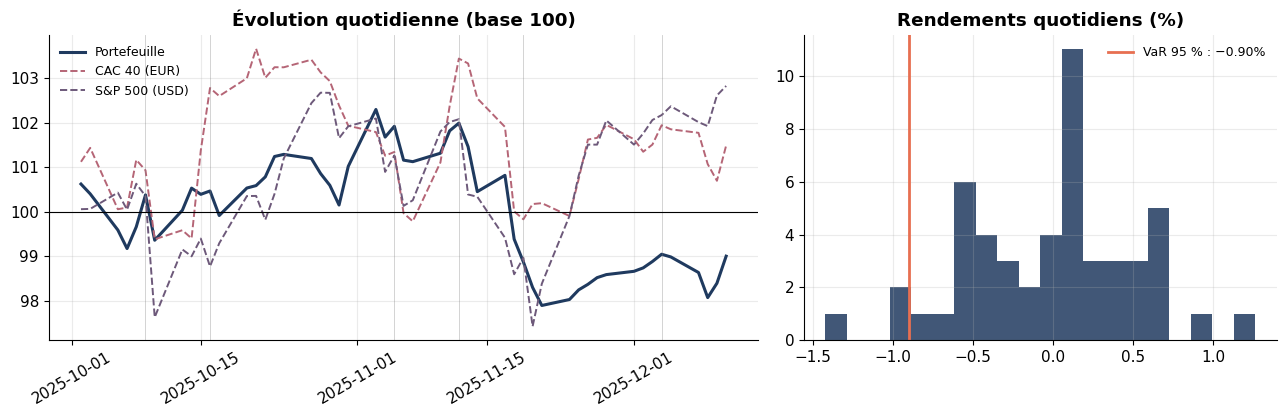

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [3, 2]})
ax1.plot((1 + r).cumprod() * 100, color=COULEURS["journalier"], lw=2.2, label="Portefeuille")
for (nom, x), c in zip(r_ind.items(), [COULEURS["cac"], COULEURS["sp"]]):
    ax1.plot((1 + x).cumprod() * 100, color=c, lw=1.4, ls="--", label=f"{nom} ({'USD' if 'S&P' in nom else 'EUR'})")
for d in semaines.date_debut.iloc[1:]:
    ax1.axvline(d, color="grey", lw=0.6, alpha=0.4)
ax1.axhline(100, color="black", lw=0.8)
ax1.set_title("Évolution quotidienne (base 100)"); ax1.legend(frameon=False, fontsize=9)
ax1.tick_params(axis="x", rotation=30)

var95 = -np.percentile(r, 5)
ax2.hist(r * 100, bins=20, color=COULEURS["journalier"], alpha=0.85)
ax2.axvline(-var95 * 100, color=COULEURS["var"], lw=2, label=f"VaR 95 % : −{var95:.2%}")
ax2.set_title("Rendements quotidiens (%)"); ax2.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

Les traits verticaux gris marquent les changements de composition du portefeuille (début de chaque semaine). Le rendement cumulé quotidien peut différer un peu du capital final de la section 5 : il utilise les clôtures Yahoo au lieu des cours notés dans le classeur et ignore les intérêts du cash.

## 7. Grille des seuils : hebdomadaire contre journalier

On applique la règle à **toutes les lignes et toutes les semaines**, pour chaque couple de seuils, avec les deux modèles. Les positions restent celles réellement choisies chaque semaine.

Si le biais décrit dans le premier notebook est réel, la grille journalière doit pénaliser les stop-loss serrés : les baisses passagères déclenchent maintenant des ventes.

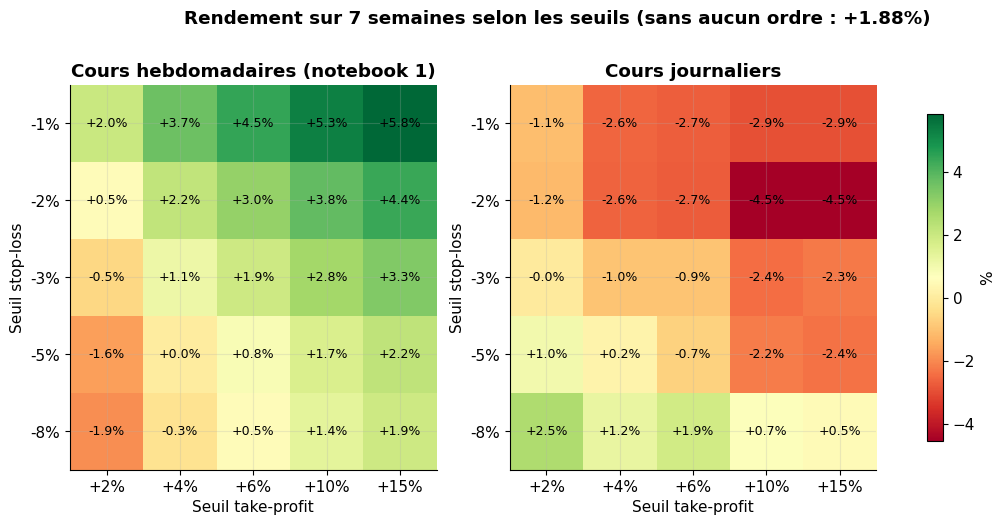

In [12]:
grille_sl = [0.99, 0.98, 0.97, 0.95, 0.92]
grille_tp = [1.02, 1.04, 1.06, 1.10, 1.15]
lignes_lbl, colonnes_lbl = [f"-{1 - s:.0%}" for s in grille_sl], [f"+{t - 1:.0%}" for t in grille_tp]
grilles = {}
for mode in ["hebdo", "journalier"]:
    g = pd.DataFrame(index=lignes_lbl, columns=colonnes_lbl, dtype=float)
    for s, ls in zip(grille_sl, lignes_lbl):
        for t, ct in zip(grille_tp, colonnes_lbl):
            res, _ = simuler(mode=mode, regle="toutes", seuil_sl=s, seuil_tp=t, execution_notee=False)
            g.loc[ls, ct] = res.capital_fin.iloc[-1] / CAPITAL_INITIAL - 1
    grilles[mode] = g
reference = sims["sans"][0].capital_fin.iloc[-1] / CAPITAL_INITIAL - 1

vmin = min(g.values.min() for g in grilles.values()) * 100
vmax = max(g.values.max() for g in grilles.values()) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (mode, g) in zip(axes, grilles.items()):
    im = ax.imshow(g.values * 100, cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(colonnes_lbl)), colonnes_lbl); ax.set_yticks(range(len(lignes_lbl)), lignes_lbl)
    ax.set_xlabel("Seuil take-profit"); ax.set_ylabel("Seuil stop-loss")
    for i in range(len(lignes_lbl)):
        for k in range(len(colonnes_lbl)):
            ax.text(k, i, f"{g.values[i, k]:+.1%}", ha="center", va="center", fontsize=9)
    ax.set_title("Cours hebdomadaires (notebook 1)" if mode == "hebdo" else "Cours journaliers")
fig.suptitle(f"Rendement sur 7 semaines selon les seuils (sans aucun ordre : {reference:+.2%})", fontweight="bold", y=1.03)
fig.colorbar(im, ax=axes, label="%", shrink=0.85)
plt.show()

**Questions pour lire la grille**

- Le coin « stop-loss −1 % » est-il toujours aussi vert avec les cours journaliers ?
- Existe-t-il des couples de seuils qui battent « sans aucun ordre » dans les deux grilles ? Si c'est le cas sur 7 semaines seulement, ce n'est pas encore une preuve : il faudrait tester sur une autre période (hors échantillon).

## 8. Limites et pistes

- **Ordre des cours dans la journée inconnu** : quand les deux seuils sont touchés le même jour, on suppose le stop-loss en premier.
- **Pas de frais de transaction ni de dividendes**, et une valorisation quotidienne sans les intérêts courus du cash.
- **Pistes** : ajouter des frais (par exemple 0,1 % par ordre), tester la règle sur une autre période, comparer à un portefeuille équipondéré.